# Benchmark relationnel

Chaque question porte sur un petit graphe tiré d'OSM :
- les nœuds sont des POIs, reconnus par leur id « nom (catégorie) » ;
- une relation va d'un POI vers un autre : une distance en mètres et une direction, gardée de deux façons :
  en degrés (0° = nord, dans le sens des aiguilles d'une montre) et parmi huit points cardinaux (north, northeast, east, southeast, south, southwest, west, northwest).
  `FORMAT_DIRECTION` (`config/relational.py`) choisit celle qui est écrite dans les questions.

Une relation du graphe est cachée : c'est la réponse que le modèle doit retrouver à partir des autres.
Sans elle, ses deux POIs sont reliés par un plus court chemin de `path_length` relations, lues dans les deux sens.

Le tableau a une ligne par question : `graph`, `path` (le sous-graphe du plus court chemin), `questions`, `answer`,
et deux labels, `label_cardinal` et `label_degrees`. `check_benchmark` vérifie qu'en mettant bout à bout
les relations du chemin, on retrouve bien la réponse.
Il compare aussi la réponse trouvée avec les degrés et celle trouvée avec les seuls points cardinaux des relations.

In [ ]:
from benchmark_pipeline.config import CITY_BBOXES, CITY_ECRS
from benchmark_pipeline.generator.relational.control import check_benchmark
from benchmark_pipeline.generator.relational.generator_relational import create_benchmark
from benchmark_pipeline.generator.relational.viz import plot_graph
from benchmark_pipeline.loader.data_cleaning.name_matching import name_matching_cleaning
from benchmark_pipeline.loader.osm_loaders import load_tables

In [14]:
# la zone : les POIs d'une ville, avec des noms uniques et une géométrie en mètres
ville = "Paris"
df_osm, df_street, df_area = load_tables(CITY_BBOXES[ville], CITY_ECRS[ville], city_name=ville)
_, (pois_zone, _, _) = name_matching_cleaning(df_osm, df_street, df_area)
print(len(pois_zone), "POIs dans la zone")

/Users/sese/Documents/code/benchmark_pipeline/benchmark_pipeline/loader/osm_extractor.py:156: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  pois["geometry"] = pois.geometry.centroid


75 morceaux de rue recollés
lignes supprimées par source : {'street': 2, 'poi': 2}
16012 POIs dans la zone


In [15]:
benchmark = create_benchmark(pois_zone, nb_questions=10, nb_pois=50, nb_relations=70, path_length=10)
print(benchmark.loc[0, "questions"])
print("réponse :", benchmark.loc[0, "answer"])
print("labels :", benchmark.loc[0, "label_cardinal"], benchmark.loc[0, "label_degrees"])
benchmark.head()

Le poi Tina au 38 (bar) est à 1331 m et en direction sud-ouest vers le poi Pho 21 (restaurant).
Le poi Les Amateurs (restaurant) est à 2745 m et en direction sud-ouest vers le poi Café Léon (bar).
Le poi Les Frères Bretons (restaurant) est à 299 m et en direction sud-est vers le poi Ibis Paris Tour Eiffel Cambronne 15ème (hotel).
Le poi Golden Wok (restaurant) est à 8074 m et en direction sud-ouest vers le poi The Lions (pub).
Le poi Yard (restaurant) est à 551 m et en direction sud vers le poi Bao Bao (restaurant).
Le poi Oky Sushi (restaurant) est à 7571 m et en direction nord-est vers le poi La Table des Caves (restaurant).
Le poi Café Gallery (cafe) est à 1570 m et en direction est vers le poi Gemlik (restaurant).
Le poi Le Phenix (restaurant) est à 6889 m et en direction ouest vers le poi Bubble tea bar (cafe).
Le poi Jyl Café (cafe) est à 2383 m et en direction sud-ouest vers le poi Restaurant Bayan (restaurant).
Le poi Les Lilas (restaurant) est à 1111 m et en direction ouest ve

,graphe,chemin,questions,reponse,label_cardinal,label_degres
0,{'pois': ['Boulettes Chef Sandwich (restaurant...,"{'pois': ['Les Frères Bretons (restaurant)', '...",Le poi Tina au 38 (bar) est à 1331 m et en dir...,"{'depuis': 'Les Frères Bretons (restaurant)', ...","{'distance': 1971, 'direction': 'sud-est'}","{'distance': 1971, 'direction': 120}"
1,"{'pois': ['Amalfi (restaurant)', 'Luisa Maria ...","{'pois': ['La Belle Table (restaurant)', 'Amal...",Le poi Ibis Paris Porte de Montreuil (hotel) e...,"{'depuis': 'La Belle Table (restaurant)', 'ver...","{'distance': 4701, 'direction': 'nord-ouest'}","{'distance': 4701, 'direction': 305}"
2,"{'pois': ['Vanilla Café (bar)', 'Hôtel CourSei...","{'pois': ['Hôtel du Delta (hotel)', 'China Tow...",Le poi Bistrot des Amis (restaurant) est à 483...,"{'depuis': 'Hôtel du Delta (hotel)', 'vers': '...","{'distance': 2606, 'direction': 'sud'}","{'distance': 2606, 'direction': 180}"
3,"{'pois': ['Café Jaby (cafe)', 'BOKBAR (cafe)',...","{'pois': ['Casa San Pablo (restaurant)', 'Le P...",Le poi Bistrot Richelieu (restaurant) est à 21...,"{'depuis': 'Casa San Pablo (restaurant)', 'ver...","{'distance': 929, 'direction': 'nord-ouest'}","{'distance': 929, 'direction': 299}"
4,"{'pois': ['Le Saint-Fargeau (cafe)', 'Burgundy...","{'pois': ['Le 46 (restaurant)', 'PB Originals ...",Le poi Hôtel Montsouris Orléans (hotel) est à ...,"{'depuis': 'Le 46 (restaurant)', 'vers': 'La T...","{'distance': 5163, 'direction': 'est'}","{'distance': 5163, 'direction': 84}"


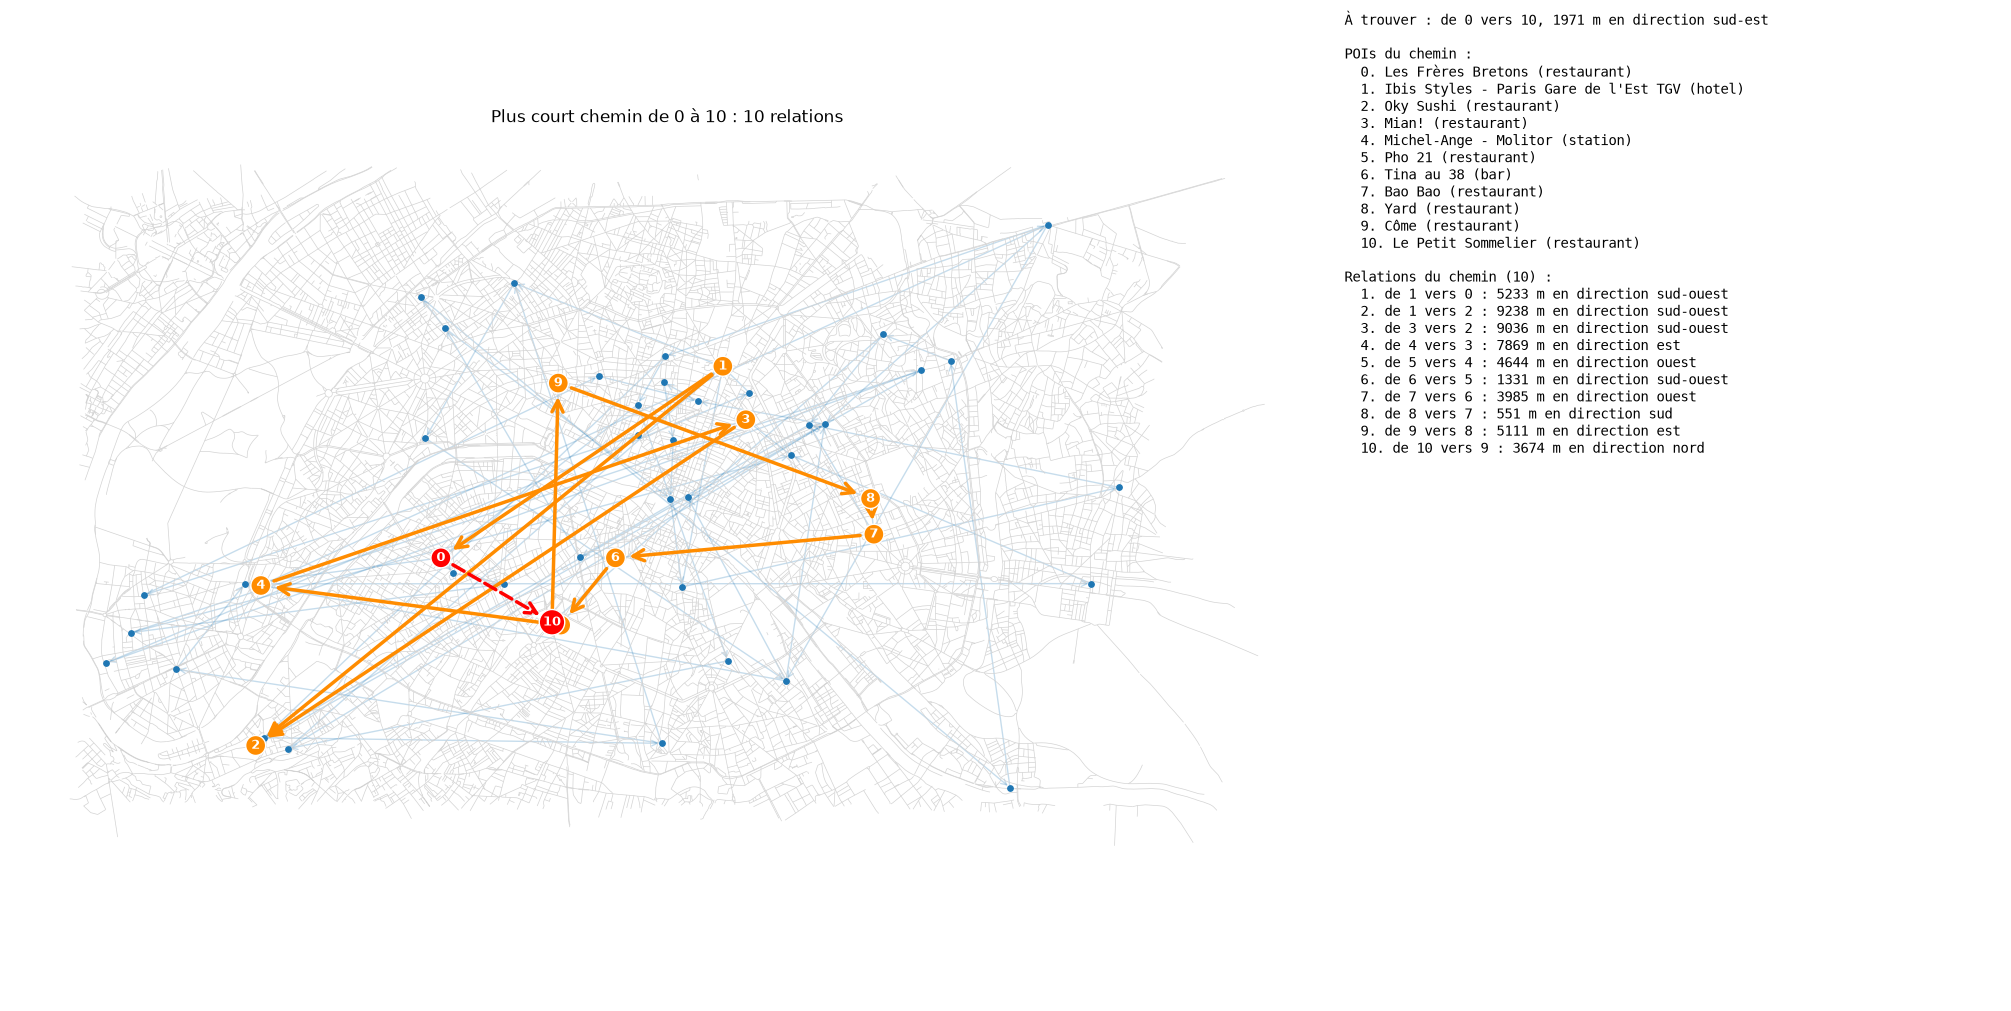

In [16]:
question = 0
plot_graph(benchmark.loc[question, "graph"], benchmark.loc[question, "answer"], df_street)

In [17]:
controle = check_benchmark(benchmark)
controle

distances retrouvées : 10 / 10
angles retrouvés : 10 / 10 questions vérifiables
labels cardinaux retrouvés : 10 / 10 questions vérifiables
questions non vérifiables : 0 (réponse plus courte que l'écart permis par les arrondis)


,question,angle_calcule,angle_attendu,ecart_angle,ecart_angle_permis,distance_calculee,distance_attendue,ecart_distance,ecart_distance_permis,label_cardinal,verifiable,angle_ok,distance_ok,cardinal_ok
0,0,122.3,120,2.3,13.6,1937,1971,33.6,447.7,sud-est,True,True,True,True
1,1,306.4,305,1.4,7.2,4760,4701,59.4,551.8,nord-ouest,True,True,True,True
2,2,181.7,180,1.7,8.9,2535,2606,71.3,380.0,sud,True,True,True,True
3,3,295.0,299,4.0,24.6,951,929,21.6,379.3,nord-ouest,True,True,True,True
4,4,84.6,84,0.6,3.8,5114,5163,48.5,300.0,est,True,True,True,True
5,5,252.6,253,0.4,9.3,2153,2196,43.3,335.8,ouest,True,True,True,True
6,6,127.5,128,0.5,3.9,9740,9666,73.5,580.1,sud-est,True,True,True,True
7,7,143.1,141,2.1,12.2,2946,2857,88.9,578.0,sud-est,True,True,True,True
8,8,49.6,50,0.4,2.9,7607,7628,21.2,317.3,nord-est,True,True,True,True
9,9,315.8,318,2.2,9.8,2035,2064,28.8,335.6,nord-ouest,True,True,True,True
